# Measurement Points

In this example we showcase the functionality of adding measurement points to the model. Measurement points can be added to monitor the temperature at position $(x,y)$ in the environment.

Measurement points can be added to a `StaticEnvSoil` only. To add a measurement point, we start by constructing a static environment. Refer to the [Example Calculation](./../example_calculation) for a step by step guide on setting up a model.

In [ ]:
from datetime import datetime
from importlib.resources import files
from pathlib import Path

import numpy as np
import pandas as pd

from cable_thermal_model import CableLayer, CablePosition, ModelFactory, StaticEnvSoil
from cable_thermal_model.cable.schemas.circuit_schemas import CircuitInSoilFromCableIdInputSchema

example_cables_csv_path = Path(str(files("data").joinpath("example_cables.csv")))

static_env = StaticEnvSoil()

circuit_input_1 = CircuitInSoilFromCableIdInputSchema(
    x=0.0,
    y=-1,
    circuit_name="circuit_1",
    cable_id="GPLK 10/10 kV 3x185 Al",
    cable_source_file_path=example_cables_csv_path,
)
static_env.add_circuit_from_cable_id(circuit_input_1)

With a static environment set, we can add one or multiple measurement points. The measurement keys can be used to retrieve the temperature profile after running the model.

In [ ]:
measurement_point_key1 = static_env.add_measurement_point(x=0.1, y=-1.0)
measurement_point_key2 = static_env.add_measurement_point(x=0.3, y=-1.0)

print(f"Measurement Point Key 1: {measurement_point_key1}")
print(f"Measurement Point Key 2: {measurement_point_key2}")

Measurement Point Key 1: ('measurement_point', 'x=0.100m', 'y=-1.000m')
Measurement Point Key 2: ('measurement_point', 'x=0.300m', 'y=-1.000m')


Now, a scenario and a model can be set up.

In [ ]:
# In this case we use a scenario that lasts for a week with a step size of 1 hour.
START_DATE = datetime(2026, 1, 1)
DAYS_TO_SIMULATE = 7

scenario = pd.DataFrame(
    index=pd.date_range(start=START_DATE, end=START_DATE + pd.Timedelta(days=DAYS_TO_SIMULATE), freq="1h")
)

# We set the load of the circuit to oscillate between 50 and 350A with a period of 24 hours.
scenario["load_circuit_1"] = 200.0 + 150.0 * np.sin(2 * np.pi * scenario.index.hour / 24)
scenario["ambient_temperature"] = 15.0  # Ambient temperature is assumed to be constant at 15 degrees Celsius.
scenario["soil_thermal_resistivity"] = 0.75  # Soil thermal resistivity is assumed to be constant at 0.75 mK/W.
scenario["soil_thermal_capacity"] = 2.0e6  # Soil thermal capacity is assumed to be constant at 2e6 J/(m³K).

scenario.head()

,load_circuit_1,ambient_temperature,soil_thermal_resistivity,soil_thermal_capacity
2026-01-01 00:00:00,200.000000,15.0,0.75,2000000.0
2026-01-01 01:00:00,238.822857,15.0,0.75,2000000.0
2026-01-01 02:00:00,275.000000,15.0,0.75,2000000.0
2026-01-01 03:00:00,306.066017,15.0,0.75,2000000.0
2026-01-01 04:00:00,329.903811,15.0,0.75,2000000.0


The model can be executed to compute the temperature profile over time.

The simulation output is stored in `solution`, and the temperature time series are available in `temperature_result`.  
This includes cable temperatures (e.g., conductor and sheath) as well as temperatures at the added measurement points.

In [ ]:
model = ModelFactory.create_model(static_env=static_env)

solution = model.run(scenario=scenario)
temperature_result = solution.result

temperature_result.head()

circuit_1            measurement_point           
                        single                     x=0.300m   x=0.100m
                     Conductor     Sheath         y=-1.000m  y=-1.000m
2026-01-01 00:00:00  15.000000  15.000000         15.000000  15.000000
2026-01-01 01:00:00  24.560415  16.688139         15.002660  15.262842
2026-01-01 02:00:00  31.931968  18.657860         15.013090  15.755987
2026-01-01 03:00:00  38.768200  20.709831         15.036841  16.407923
2026-01-01 04:00:00  45.103538  22.766946         15.078344  17.164260

The temperature profile at a measurement point can be retrieved using the forementioned keys.

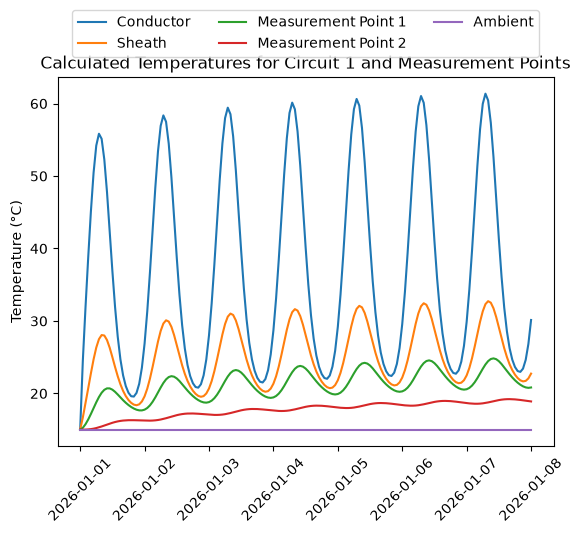

In [ ]:
import matplotlib.pyplot as plt

# Plot the measurement points together with conductor and sheath temperatures.
x = temperature_result.index
series = [
    temperature_result["circuit_1"][CablePosition.Single][CableLayer.Conductor],
    temperature_result["circuit_1"][CablePosition.Single][CableLayer.Sheath],
    temperature_result[measurement_point_key1],
    temperature_result[measurement_point_key2],
    scenario["ambient_temperature"],
]
labels = [
    "Conductor",
    "Sheath",
    "Measurement Point 1",
    "Measurement Point 2",
    "Ambient",
]

for y, label in zip(series, labels, strict=True):
    plt.plot(x, y, label=label)

plt.ylabel("Temperature (°C)")
plt.title("Calculated Temperatures for Circuit 1 and Measurement Points")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=3)
plt.xticks(rotation=45)
plt.show()